# FL-ATTACK-003.7 — Adaptive (defence-aware, omniscient) attacks

*Epic EPIC-001 · story fl_attack_003 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Test whether the defences that worked against static attacks (task 3.2/3.5) survive attackers that see the benign updates and adapt: ALIE, MIN-MAX, norm-matched backdoor, MIN-MAX backdoor.

## 2. Scientific background
ALIE shifts malicious updates by a small multiple of the benign standard deviation [baruch2019]; MIN-MAX/AGR-tailored attacks keep malicious updates inside the benign distance envelope [shejwalkar2021]; backdoors can be rescaled to pass norm bounds [bagdasaryan2020, sun2019, wang2020tail].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Do median, trimmed mean, Krum/Multi-Krum, median-norm clipping and the anomaly filter keep accuracy under ALIE/MIN-MAX?
- **RQ2.** Do norm- or distance-constrained backdoors defeat the defences that stopped the static backdoor?

## 4. Hypotheses
- **H1.** At least one defence that performed well against static attacks degrades under an adaptive attack.
- **H2.** A norm-matched backdoor passes norm-based defences.

## 5. Mathematical formulation
ALIE: v = mu - z*sigma, z = Phi^{-1}((n-s)/n), s = floor(n/2+1) - f. MIN-MAX: v = mu + gamma p with gamma = max{g: max_i ||mu + g p - b_i|| <= max_{i,j} ||b_i - b_j||}, p = -mu/||mu||. Norm-matched backdoor: d' = d * median_i||b_i|| / ||d||. MIN-MAX backdoor: p = d_m - mu.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_attack_003"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_attack_003


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`attacks_adaptive.py`, `defenses.py`, `fl.py`, `experiments/ext.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.attacks.adaptive import alie_z, alie_vector, minmax_vector, minmax_gamma, _max_pairwise
r = np.random.default_rng(SEED); B = r.normal(1.0, 0.3, (16, 50)).astype(np.float32)
print("ALIE z (n=20, f=4):", round(alie_z(20, 4), 4))
mu = B.mean(0); p = -mu / np.linalg.norm(mu); g = minmax_gamma(B, mu, p); thr = _max_pairwise(B)
print("min-max gamma:", round(g, 3), "| max distance to benign:", round(float(np.linalg.norm(mu + g * p - B, axis=1).max()), 3), "<= benign max pairwise:", round(thr, 3))
assert np.linalg.norm(mu + g * p - B, axis=1).max() <= thr * (1 + 1e-9)

ALIE z (n=20, f=4): 0.3853
min-max gamma: 2.781 | max distance to benign: 3.947 <= benign max pairwise: 3.947


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-ATTACK-003.7` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_3_7_untargeted_runs.csv')
show_csv('task_3_7_backdoor_runs.csv')

,dataset,seed,defense,attack,acc,f1,auc
0,syn,0,mean,none,0.7781,0.7053,0.8524
1,syn,0,mean,alie,0.7808,0.7092,0.8522
2,syn,0,mean,minmax,0.7553,0.6669,0.8259
3,syn,0,median,none,0.7767,0.7024,0.8506
4,syn,0,median,alie,0.7753,0.7005,0.8473
5,syn,0,median,minmax,0.7592,0.6754,0.8277
6,syn,0,trimmed_mean,none,0.7769,0.7036,0.8511
7,syn,0,trimmed_mean,alie,0.7781,0.7044,0.8495
8,syn,0,trimmed_mean,minmax,0.7597,0.6727,0.8280
9,syn,0,krum,none,0.7692,0.6966,0.8403


,dataset,seed,defense,attack,asr,clean_acc
0,syn,0,mean,none_clean,0.1174,0.7781
1,syn,0,mean,static_boost,0.9965,0.7408
2,syn,0,mean,norm_matched,0.8253,0.7653
3,syn,0,mean,minmax_backdoor,0.7348,0.7750
4,syn,0,median,none_clean,0.1305,0.7767
5,syn,0,median,static_boost,0.2700,0.7783
6,syn,0,median,norm_matched,0.2693,0.7708
7,syn,0,median,minmax_backdoor,0.2901,0.7747
8,syn,0,trimmed_mean,none_clean,0.1354,0.7769
9,syn,0,trimmed_mean,static_boost,0.3115,0.7767


## 12. Metrics collection
Metric definitions: test accuracy/F1/AUC (untargeted) and backdoor ASR + clean accuracy; mean and t-CI over 5 seeds; threat model is OMNISCIENT (upper bound on attacker knowledge).

In [8]:
show_csv('task_3_7_untargeted_summary.csv', 30)

,dataset,defense,attack,n,acc,acc_ci,f1,f1_ci,auc,auc_ci
0,heart,mean,none,5,0.8462,"[0.827, 0.865]",0.8614,"[0.841, 0.882]",0.9063,"[0.898, 0.915]"
1,heart,mean,alie,5,0.8330,"[0.802, 0.864]",0.8474,"[0.813, 0.882]",0.9041,"[0.899, 0.909]"
2,heart,mean,minmax,5,0.8154,"[0.771, 0.860]",0.8312,"[0.785, 0.877]",0.8952,"[0.886, 0.905]"
3,heart,median,none,5,0.8484,"[0.831, 0.866]",0.8641,"[0.844, 0.884]",0.9068,"[0.898, 0.915]"
4,heart,median,alie,5,0.8374,"[0.801, 0.874]",0.8518,"[0.812, 0.891]",0.9060,"[0.902, 0.910]"
5,heart,median,minmax,5,0.8308,"[0.795, 0.866]",0.8445,"[0.807, 0.882]",0.9001,"[0.889, 0.912]"
6,heart,trimmed_mean,none,5,0.8462,"[0.827, 0.865]",0.8618,"[0.840, 0.884]",0.9071,"[0.899, 0.915]"
7,heart,trimmed_mean,alie,5,0.8440,"[0.814, 0.874]",0.8577,"[0.826, 0.890]",0.9061,"[0.901, 0.911]"
8,heart,trimmed_mean,minmax,5,0.8198,"[0.797, 0.843]",0.8370,"[0.813, 0.861]",0.8969,"[0.884, 0.910]"
9,heart,krum,none,5,0.8352,"[0.816, 0.854]",0.8519,"[0.833, 0.871]",0.9015,"[0.884, 0.919]"


## 13. Statistical analysis
t-intervals over seeds; no multiple-comparison testing is claimed for this task (descriptive).

In [9]:
show_csv('task_3_7_backdoor_summary.csv', 30)

,dataset,defense,attack,n,asr,asr_ci,clean_acc,clean_acc_ci
0,syn,mean,none_clean,5,0.1064,"[-0.013, 0.226]",0.7772,"[0.772, 0.783]"
1,syn,mean,static_boost,5,0.9978,"[0.997, 0.999]",0.7378,"[0.729, 0.746]"
2,syn,mean,norm_matched,5,0.7532,"[0.577, 0.929]",0.7607,"[0.755, 0.766]"
3,syn,mean,minmax_backdoor,5,0.6363,"[0.381, 0.892]",0.7704,"[0.762, 0.778]"
4,syn,median,none_clean,5,0.1133,"[-0.014, 0.240]",0.7767,"[0.770, 0.783]"
5,syn,median,static_boost,5,0.2606,"[0.015, 0.506]",0.7742,"[0.765, 0.783]"
6,syn,median,norm_matched,5,0.2568,"[0.037, 0.477]",0.7658,"[0.758, 0.774]"
7,syn,median,minmax_backdoor,5,0.2662,"[0.029, 0.503]",0.7706,"[0.763, 0.778]"
8,syn,trimmed_mean,none_clean,5,0.1138,"[-0.014, 0.241]",0.7756,"[0.768, 0.783]"
9,syn,trimmed_mean,static_boost,5,0.2883,"[0.032, 0.545]",0.7725,"[0.764, 0.781]"


## 14. Visualizations

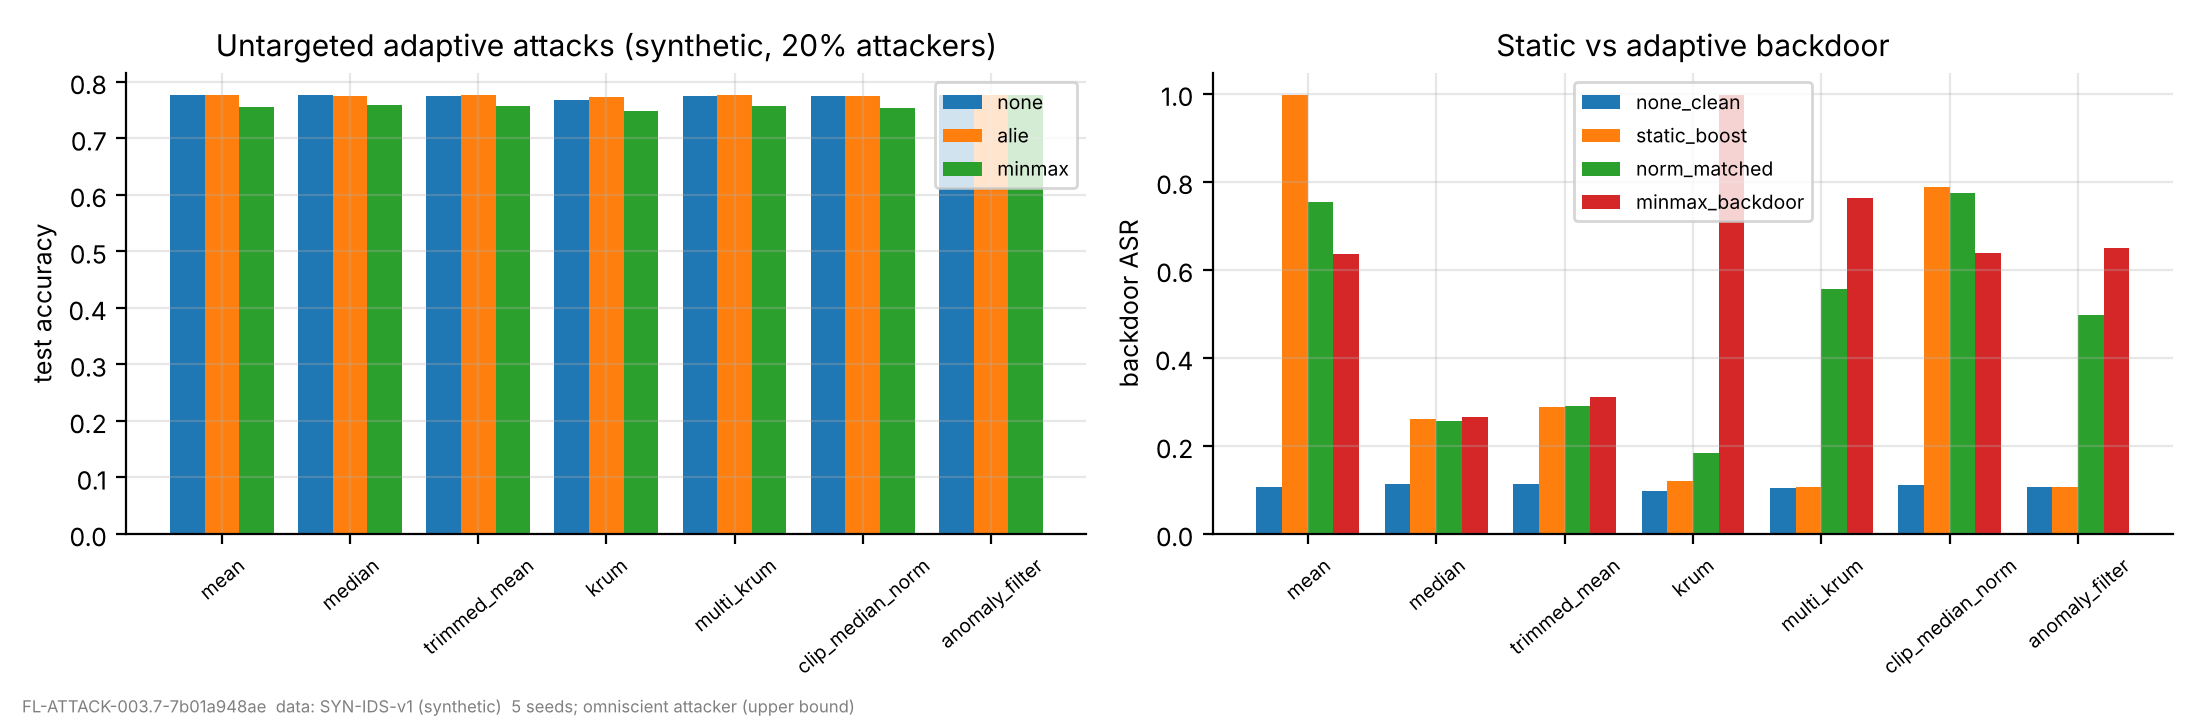

In [10]:
show_fig('task_3_7_adaptive.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Printed tables show, per defence, accuracy/ASR with no attack, with the adaptive attack and (backdoor) with the static attack; the interpretation in results_and_discussion.md is limited to those numbers.

In [11]:
d = pd.read_csv(RES / 'task_3_7_untargeted_summary.csv'); print(d[d.dataset=='syn'].pivot_table(index='defense', columns='attack', values='acc').round(3).to_string()); b = pd.read_csv(RES / 'task_3_7_backdoor_summary.csv'); print(b.pivot_table(index='defense', columns='attack', values='asr').round(3).to_string())

attack             alie  minmax   none
defense                               
anomaly_filter    0.777   0.777  0.777
clip_median_norm  0.775   0.753  0.774
krum              0.774   0.749  0.768
mean              0.777   0.756  0.777
median            0.775   0.758  0.777
multi_krum        0.776   0.757  0.775
trimmed_mean      0.776   0.758  0.776
attack            minmax_backdoor  none_clean  norm_matched  static_boost
defense                                                                  
anomaly_filter              0.649       0.107         0.498         0.106
clip_median_norm            0.639       0.111         0.775         0.788
krum                        0.996       0.097         0.184         0.120
mean                        0.636       0.106         0.753         0.998
median                      0.266       0.113         0.257         0.261
multi_krum                  0.763       0.104         0.557         0.106
trimmed_mean                0.311       0.114         0.2

## 16. Limitations
- Omniscient attacker = upper bound; attacks are not optimised per defence beyond their constraints.
- Real-data settings are small (K=10, f=2) and untargeted only; the backdoor study is synthetic only.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Static-attack robustness does not imply adaptive-attack robustness; see results_and_discussion.md for which defences held.

**Jira acceptance:** see `docs/fl_attack_003/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`baruch2019`, `shejwalkar2021`, `bagdasaryan2020`, `sun2019`, `blanchard2017`, `yin2018` — details in `docs/fl_attack_003/references.md`.